# Cornell A: text curation, conservative dates and leakage validation

Executed October 15, 2026. Current study: original **4,052** targets → **3,627** conditional research rows.
This reuses the existing interviews, structured sources and notebooks. No new large data, official-code edit,
E5 model, TAR run, email or push. Actual local TF-IDF diagnostics are clearly distinguished below.
[Leakage report](../reports/tennis_a_leakage_validation.md) · [Text report](../reports/tennis_a_text_preprocessing.md).


In [1]:
import json
from pathlib import Path
import sys
project=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'tennis/scripts').is_dir())
if str(project) not in sys.path:sys.path.insert(0,str(project))
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from tennis.scripts.common import OUT
from tennis.scripts.a_study import STUDY
review=json.loads((OUT/'a_v1_review_summary.json').read_text())
audit=json.loads((OUT/'a_v1_leakage_summary.json').read_text())
checks=pd.read_csv(OUT/'a_v1_leakage_checks.csv')
display(pd.DataFrame([review]))
print('Private candidate directory:',STUDY)
print('Conditional date rule: >=3 calendar days; this is NOT verified publication.')


,original_rows,v1_rows,excluded_rows,both_sources_immediate_previous_match,at_least_one_source_immediate_previous_match,median_interview_age_a_days,median_interview_age_b_days,completed_local_diagnostic_fits,superseded_debug_fits_before_scoring,reserved_test_model_scores,tokenizer_model_revision
0,4052,3627,425,70,385,28.0,28.0,13,2,0,ffb93f3bd4047442299a41ebb6fa998a38507c52


Private candidate directory: /Users/dimabshara/Desktop/NLP/tennis-research-cache/derived/candidate_A_v1
Conditional date rule: >=3 calendar days; this is NOT verified publication.


,lag_days,original_target_pool,retained_rows,excluded_rows,rows_using_older_eligible_interview,publication_verified_rows,rule_is_assumption,rows_both_sources_are_immediate_previous_match,rows_any_source_is_immediate_previous_match
0,1,4052,4037,15,46,0,True,836.0,1894.0
1,2,4052,3857,195,661,0,True,439.0,1187.0
2,3,4052,3627,425,1219,0,True,70.0,385.0
3,7,4052,3360,692,1335,0,True,17.0,191.0


,lag_days,interview_next_match_links,unique_next_target_matches,links_in_original_4052_pool,not_a_two_sided_match_dataset_count
0,1,5869,5029,2735,True
1,2,4273,3832,1650,True
2,3,2166,2095,474,True
3,7,1481,1463,230,True


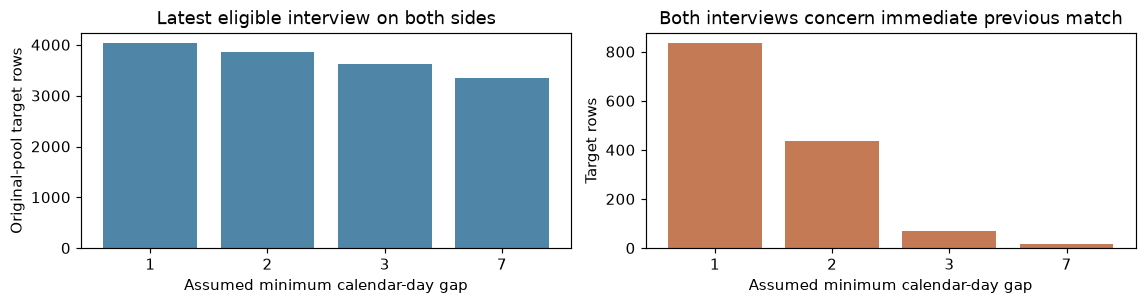

,partition,rows,first_day,last_day
0,train,2162,2007-01-19,2012-10-12
1,development,716,2012-10-13,2014-06-18
2,reserved_test,749,2014-06-19,2015-11-22


In [2]:
dates=pd.read_csv(OUT/'a_v1_date_sensitivity.csv')
display(dates)
display(pd.read_csv(OUT/'a_v1_next_match_counts.csv'))
fig,axes=plt.subplots(1,2,figsize=(11,3))
axes[0].bar(dates.lag_days.astype(str),dates.retained_rows,color='#4f86a8')
axes[0].set(title='Latest eligible interview on both sides',xlabel='Assumed minimum calendar-day gap',ylabel='Original-pool target rows')
axes[1].bar(dates.lag_days.astype(str),dates.rows_both_sources_are_immediate_previous_match,color='#c47a55')
axes[1].set(title='Both interviews concern immediate previous match',xlabel='Assumed minimum calendar-day gap',ylabel='Target rows')
plt.tight_layout();plt.show()
display(pd.read_csv(OUT/'a_v1_split_summary.csv'))


**Insight:** a next-match association is possible. Exact upload times are not supplied, so a declared calendar
buffer supports conditional research. Selecting an older eligible interview retains 3,627 rows under three days;
simply dropping a too-recent latest interview would lose more. Only 70 retained rows have both source interviews
attached to the immediate previous match. Most use older documents, weakening a fresh-fatigue interpretation.
A one-player next-match link count is not a two-sided dataset size. The delay is an assumption, not proof.


,policy,training_documents,median_formatted_tokens,max_formatted_tokens,legacy_over_limit_docs,condition_retention,tactics_retention,preparation_retention,mentality_retention,surface_retention
0,legacy300,2011,389.0,461,0,0.588963,0.840188,0.538868,0.677816,0.543124
1,token_head,2011,512.0,512,0,0.679353,0.894242,0.643774,0.765188,0.632867
2,head_tail,2011,501.0,512,0,0.634634,0.854289,0.667170,0.741297,0.637529
3,topical_answers,2011,182.0,512,0,1.000000,1.000000,1.000000,0.997952,0.997669
4,topical_qa,2011,459.0,512,0,1.000000,1.000000,1.000000,0.998635,0.997669
5,qa_blocks,2011,446.0,512,0,0.981922,0.985311,0.971321,0.926280,0.920746


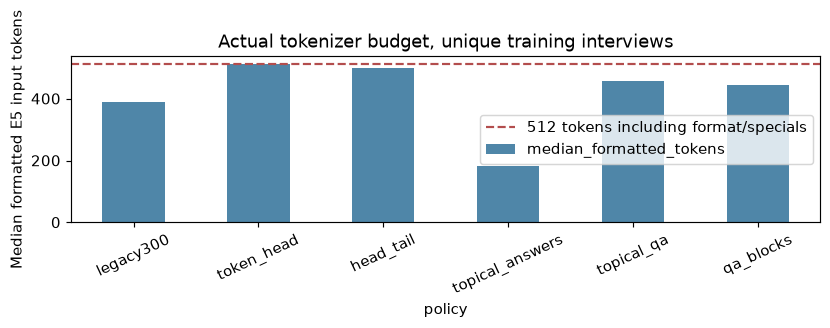

In [3]:
text=pd.read_csv(OUT/'a_v1_all_text_policies.csv')
display(text)
ax=text.set_index('policy').median_formatted_tokens.plot.bar(figsize=(8,3),color='#4f86a8',rot=25)
ax.axhline(512,color='#b34d4d',linestyle='--',label='512 tokens including format/specials')
ax.set(ylabel='Median formatted E5 input tokens',title='Actual tokenizer budget, unique training interviews')
ax.legend();plt.tight_layout();plt.show()


**Insight:** fixed first-300-word input underuses the available budget here; none of these legacy passages
exceeded the true limit. The official format and special tokens consume 10 of 512 tokens. All six variants fit.
Keyword retention is a mechanical dictionary measure, not a medical/tactical quality label or model score.
Sentence extracts often retain keywords while losing their subject, negation context or time reference.


In [4]:
examples=pd.read_csv(STUDY/'before_after_examples_private.csv')
display(examples[['interview_id','player','source_date','before_first_10_words','after_selected_12_words','what_to_notice']])
print('Source: original Cornell transcripts_matchinfo.json; exact source Q&A spans/hashes are retained privately.')
display(pd.read_csv(OUT/'a_v1_training_review_notes.csv'))


,interview_id,player,source_date,before_first_10_words,after_selected_12_words,what_to_notice
0,666,Kim Clijsters,2007-01-25,Mixed feelings. I know she played really well....,She hasn't been injured. I'm not really worryi...,The retained injury statement concerns the pre...
1,672,Anna Chakvetadze,2007-01-24,"Well, definitely Maria was today. She is stron...","During the match I felt pain, strain from the ...",Later answers describe the player’s own should...
2,673,Serena Williams,2007-01-23,"I'm a good writer, so I usually do all the","I hate that situation, and I'm tired of being ...",Tired of a situation is figurative. The Q&A co...


Source: original Cornell transcripts_matchinfo.json; exact source Q&A spans/hashes are retained privately.


,interview_id,player,source_date,what_to_notice,source
0,666,Kim Clijsters,2007-01-25,The retained injury statement concerns the pre...,Cornell original transcripts_matchinfo.json; Q...
1,672,Anna Chakvetadze,2007-01-24,Later answers describe the player’s own should...,Cornell original transcripts_matchinfo.json; Q...
2,673,Serena Williams,2007-01-23,Tired of a situation is figurative. The Q&A co...,Cornell original transcripts_matchinfo.json; Q...


**What the examples show:** Chakvetadze's later answers add a first-person account of shoulder trouble absent
from the prefix. Clijsters' retained injury statement concerns an opponent; Serena's tiredness phrase is figurative.
These are purposefully selected training examples, not a representative prevalence audit. Whole-answer blocks were
added as a separately frozen curation probe after inspecting training-context failures. No hypothetical injury
description is substituted for an actual quote. The excerpts stay short; full candidate passages stay outside Git.


,policy,joint_tfidf,text_tfidf,structured_only,joint_gain,TAR
0,head_tail,0.764021,0.599164,0.768358,-0.004338,not run
1,legacy300,0.762760,0.580083,0.768358,-0.005598,not run
2,qa_blocks,0.758571,0.581070,0.768358,-0.009787,not run
3,token_head,0.765954,0.604472,0.768358,-0.002404,not run
4,topical_answers,0.761476,0.557175,0.768358,-0.006882,not run
5,topical_qa,0.759393,0.579230,0.768358,-0.008965,not run


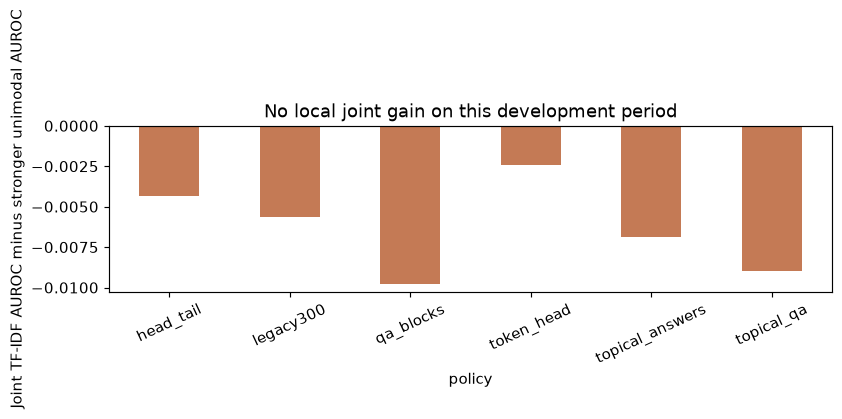

In [5]:
comparison=pd.read_csv(OUT/'a_v1_development_comparison.csv')
display(comparison)
ax=comparison.set_index('policy').joint_gain.plot.bar(figsize=(8,3),color='#c47a55',rot=25)
ax.axhline(0,color='black',linewidth=.7)
ax.set(ylabel='Joint TF-IDF AUROC minus stronger unimodal AUROC',title='No local joint gain on this development period')
plt.tight_layout();plt.show()


**Insight:** structured-only AUROC is 0.7684; every joint TF-IDF condition is below it. There is no positive
Joint Signal result here. These are 13 completed CPU logistic conditions on 2,162 train / 716 development rows,
not official E5/TAR or a five-learner curation result. The 749 reserved-test rows were not scored. Two earlier
debug fits aborted before scoring and are logged separately. High dictionary retention did not improve prediction.
The original selected policy was frozen before scores; whole blocks are a documented exploratory extension.


In [6]:
display(checks[['check_id','scenario','status','tested','violations','scope']])
print('Audit summary:',audit['by_status'])
print('Actual v1 FAIL checks:',audit['v1_actual_failures'])
print('Retained legacy/negative-control FAIL checks:',audit['retained_legacy_or_negative_control_failures'])
tests=json.loads((OUT/'a_v1_automated_test_results.json').read_text())
print('Automated boundary/adversarial tests:',tests['tests'],'successful:',tests['successful'])
display(pd.read_csv(OUT/'a_v1_history_examples.csv'))
display(pd.DataFrame([json.loads((OUT/'a_v1_mutation_results.json').read_text())]))


,check_id,scenario,status,tested,violations,scope
0,DATA01,original,PASS,4052,0,original unique target matches
1,TIME00,original,PASS,8104,0,all original A source dates strictly before ta...
2,DATA02,v1,PASS,48780,0,all raw match identities recomputed from unord...
3,TARGET01,v1,PASS,4052,0,outcome-independent A/B assignment in the enti...
4,TARGET02,v1,PASS,4052,0,original target equals oriented player's actua...
5,RANK01,v1,PASS,8104,0,original rank values attached to the correct p...
6,RANK02,v1,ASSUMPTION,7254,0,independent ranking publication timestamps
7,RANK03,v1,PASS,49745,0,entry rank constant per player/tournament/year...
8,TARGET03,v1,PASS,18,0,predictor whitelist and audit/target exclusion
9,JOIN01,v1,PASS,3324,0,only accepted interview links used


Audit summary: {'PASS': 36, 'ASSUMPTION': 6, 'FAIL': 2, 'NOT_RUN': 1}
Actual v1 FAIL checks: []
Retained legacy/negative-control FAIL checks: ['SPLIT03', 'PREP04']
Automated boundary/adversarial tests: 33 successful: True


,match_id,side,target_day,latest_history_day,past_played_matches,form10_contributor_ids,recomputed_form10,saved_form10
0,5448523514d095bee50ad237,a,2007-01-19,2007-01-17,2,ce22366d7d5a6b27e431116e|799e6416efc96aaf241f5eda,1.000000,1.000000
1,5448523514d095bee50ad237,b,2007-01-19,2007-01-17,2,9ecef759c1deee76af4a6db6|ef11a3c305347c64f93e6ff3,1.000000,1.000000
2,1c03ee62c5e791ebcc00f5c8,a,2007-01-21,2007-01-19,6,eba0025335af8ab19336b7ca|5070bfb81db5a3bb6f3c1...,0.833333,0.833333
3,1c03ee62c5e791ebcc00f5c8,b,2007-01-21,2007-01-19,13,816c5ae883d4d4e85357f0c1|c7d71e968ec7468bb243e...,0.900000,0.900000
4,46c3633d3808ef6fdf2b8e4d,a,2007-01-21,2007-01-19,8,fc99a18d62476a27d71d4fe4|cf72fc75d0f1846f0c4c0...,1.000000,1.000000
5,46c3633d3808ef6fdf2b8e4d,b,2007-01-21,2007-01-19,3,eedccaeb9d73d4dca9a87abe|f10fae52fbac198e08910...,1.000000,1.000000


,future_outcome_invariance,own_and_same_day_outcome_invariance,future_interview_invariance,train_only_vocabulary_rejects_validation_sentinel,deliberately_leaky_vocabulary_contains_sentinel,real_rows_in_future_mutation,mutation_day
0,True,True,True,True,True,100,2012-06-01


**Evidence:** the entire original target pool is checked for identity/orientation/labels/source dates; refined
histories are independently reconstructed from all raw played-match records. Future/current-day result mutation
and a future interview injection leave eligible predictors unchanged. The exported input text is compared with
its actual selected source ID, which matters when using an older interview. All text variants keep identical
structured values and targets. Statistical preprocessing/model fitting uses training row IDs only.

FAIL is intentionally retained for the legacy random forecast interpretation and a deliberately leaky vocabulary
fit. ASSUMPTION/NOT_RUN are not PASS. The JSON/CSV include why each check matters and its evidence reference.


In [7]:
print('Reuse/similarity evidence:',audit['reuse'])
display(pd.read_csv(OUT/'a_v1_reused_interview_rows.csv').head(12))
display(pd.read_csv(OUT/'a_v1_near_duplicate_screen.csv'))
from tennis.scripts.tennis_temporal_pilot import load_temporal_candidate
_,schema,train,development,basis=load_temporal_candidate(STUDY/'features_qa_blocks.csv',STUDY/'schema_qa_blocks.json')
print('Optional worker data checks accept the declared policy:',len(train),'train /',len(development),'development')
print('Availability basis:',basis)
print('Verified publication flag remains:',schema['strict_publication_temporal_gate_passed'])
print('No GPU worker/model was executed by this check.')


Reuse/similarity evidence: {'shared_interview_ids_between_partitions': 42, 'rows_using_shared_interviews': 155, 'all_shared_source_dates_before_use': True, 'identical_full_answers_across_distinct_interview_ids': 0, 'near_duplicate_pairs_at_0_95': 0, 'distinct_later_documents_screened': 1313, 'similarity_scope': 'fit-free hashed word unigram/bigram nearest training document; same IDs excluded; not exhaustive semantic similarity'}


,match_id,match_date,split,interview_id,source_date
0,8315abdb3e5a50de067e26c0,2012-08-07,train,4254,2012-07-19
1,6d16ce9dc9be7259db3f2abf,2012-08-16,train,4254,2012-07-19
2,c691f64a8bf9d86f51cb617a,2012-08-17,train,4542,2012-08-14
3,c3d1133a173a3b812ea66f7d,2012-08-19,train,4542,2012-08-14
4,b0b72e3e233d6db9bad95c28,2012-08-28,train,4254,2012-07-19
5,dc82e1733c493dc95600bfd8,2012-08-30,train,4524,2012-08-27
6,ca09e96b0138f3eadd30d7c3,2012-08-31,train,4542,2012-08-14
7,44a6e3c0d063b6c8f73c02fc,2012-09-01,train,4291,2012-08-23
8,b6956111d72c9a9681ec8876,2012-09-03,train,4496,2012-08-30
9,bd153042072ce0ed347d9375,2012-09-04,train,4475,2012-09-01


,later_interview_id,training_interview_id,hashed_word_bigram_cosine,later_source_date,training_source_date,status


Optional worker data checks accept the declared policy: 2162 train / 716 development
Availability basis: assumed calendar delay; NOT verified historical publication
Verified publication flag remains: False
No GPU worker/model was executed by this check.


**Interpretation:** 42 interview IDs cross partitions legitimately because their source events predate every use.
That dependence can reduce effective sample size without leaking a future event. Distinct documents are also
screened for exact/lexical similarity; this does not prove absence of all semantic near-duplicates.

**Remaining assumptions:** source-event linking and ranking contract; publication delay/timezones; pairing/context
known by cutoff; retrospective completed-match population; possible modern-E5 pretraining contamination. A rolling
test may use outcomes observed earlier in the test period, while keeping model parameters fixed. Their random
inner validation remains random if official classes are later used; no benchmark code is changed here.

**Recommendation:** retain token-head as a transparent baseline and context-preserving whole blocks as a curation
candidate. Do not call an extractor best because it maximizes its own keywords. Current local results give no
evidence of complementary predictive gain; leave the final test unscored and make any further development choice
explicit. Source-use/redistribution status remains recorded; there is no outreach or automatic date-based blocker.
